# 06 — Figuras para la entrega
Lee el snapshot de modelado, particiones y reportes guardados por 01–05. **No requiere sus kernels abiertos, no ejecuta otros cuadernos, no entrena y no modifica sus archivos.**

Las figuras exploratorias usan exclusivamente entrenamiento. Las figuras finales muestran predicciones de test ya congeladas: son evidencia de evaluación, no se usan para ajustar modelos. Se exportan PNG y PDF en `reports/figuras/<snapshot>/`.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
snapshot=Path(json.loads((ROOT/"configs/dataset.local.json").read_text())["snapshot"]).name
base=ROOT/"data/modelado"/snapshot
split=json.loads((base/"split/manifest.json").read_text())
manifest=json.loads((base/"manifest.json").read_text())
for archivo,sha in [(base/"datos_modelado.parquet",split["source_sha256"]),(base/"split/asignacion.parquet",split["assignment_sha256"])]:
    assert hashlib.sha256(archivo.read_bytes()).hexdigest()==sha
datos=pd.read_parquet(base/"datos_modelado.parquet")
asignacion=pd.read_parquet(base/"split/asignacion.parquet")
assert datos.index.equals(asignacion.index)
train=datos.loc[asignacion.PARTICION.eq("train")]
eda=base/"eda_train"
baseline=pd.read_csv(ROOT/"reports/baseline"/snapshot/"comparacion.csv",index_col="modelo")
tuning=pd.read_csv(ROOT/"reports/tuning"/snapshot/"comparacion_tuning.csv").set_index("modelo")
final_dir=ROOT/"reports/final"/snapshot
final=pd.read_csv(final_dir/"metricas_finales.csv").set_index("modelo")
azar=json.loads((final_dir/"referencia_aleatoria.json").read_text())
politica=json.loads((ROOT/"configs/evaluacion_final.json").read_text())
OUT=ROOT/"reports/figuras"/snapshot
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":200,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
AZUL="#2463A6";NARANJA="#DA8431"
figuras=[]
def guardar(fig,nombre):
    fig.savefig(OUT/f"{nombre}.png",bbox_inches="tight",facecolor="white")
    fig.savefig(OUT/f"{nombre}.pdf",bbox_inches="tight",facecolor="white")
    figuras.append(nombre)
    plt.show();plt.close(fig)
print("Entrenamiento:",train.shape,"| Figuras:",OUT)


Entrenamiento: (3670, 175) | Figuras: /workspace/reports/figuras/20261118T044158953530Z


## 1. Distribución del target en entrenamiento
El histograma muestra frecuencias; el boxplot usa bigotes de 1,5×IQR. Los puntos fuera de los bigotes no se eliminan automáticamente.


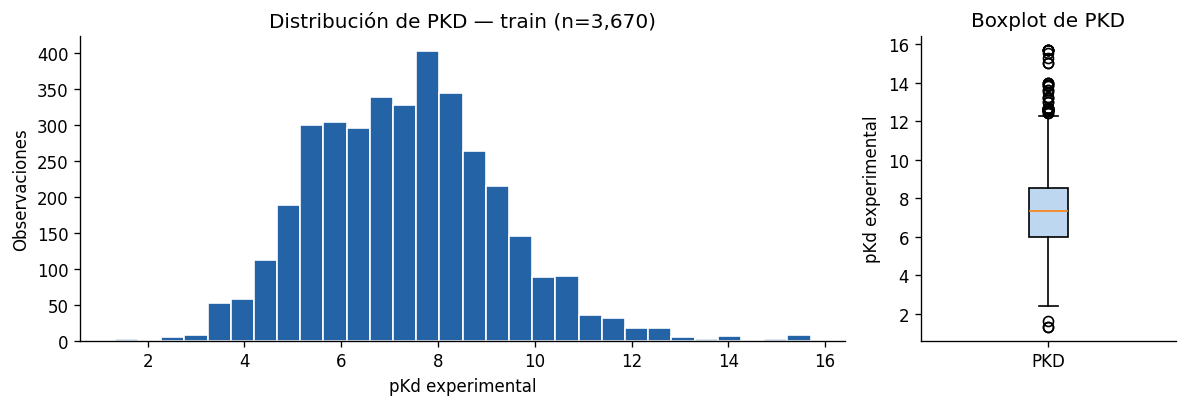

In [2]:
fig,ax=plt.subplots(1,2,figsize=(10,3.5),gridspec_kw={"width_ratios":[3,1]})
y=train[manifest["target"]].dropna()
ax[0].hist(y,bins=30,color=AZUL,edgecolor="white")
ax[0].set(xlabel="pKd experimental",ylabel="Observaciones",title=f"Distribución de PKD — train (n={len(y):,})")
ax[1].boxplot(y,whis=1.5,patch_artist=True,boxprops={"facecolor":"#BCD7EF"})
ax[1].set(xticks=[1],xticklabels=["PKD"],ylabel="pKd experimental",title="Boxplot de PKD")
fig.tight_layout();guardar(fig,"01_target_train")


## 2. Predictores con mayor asimetría
Se muestran tres variables seleccionadas por asimetría absoluta **en entrenamiento**. Cada una conserva su escala original, sin transformaciones ni imputación. El boxplot complementa las tablas IQR de 01.


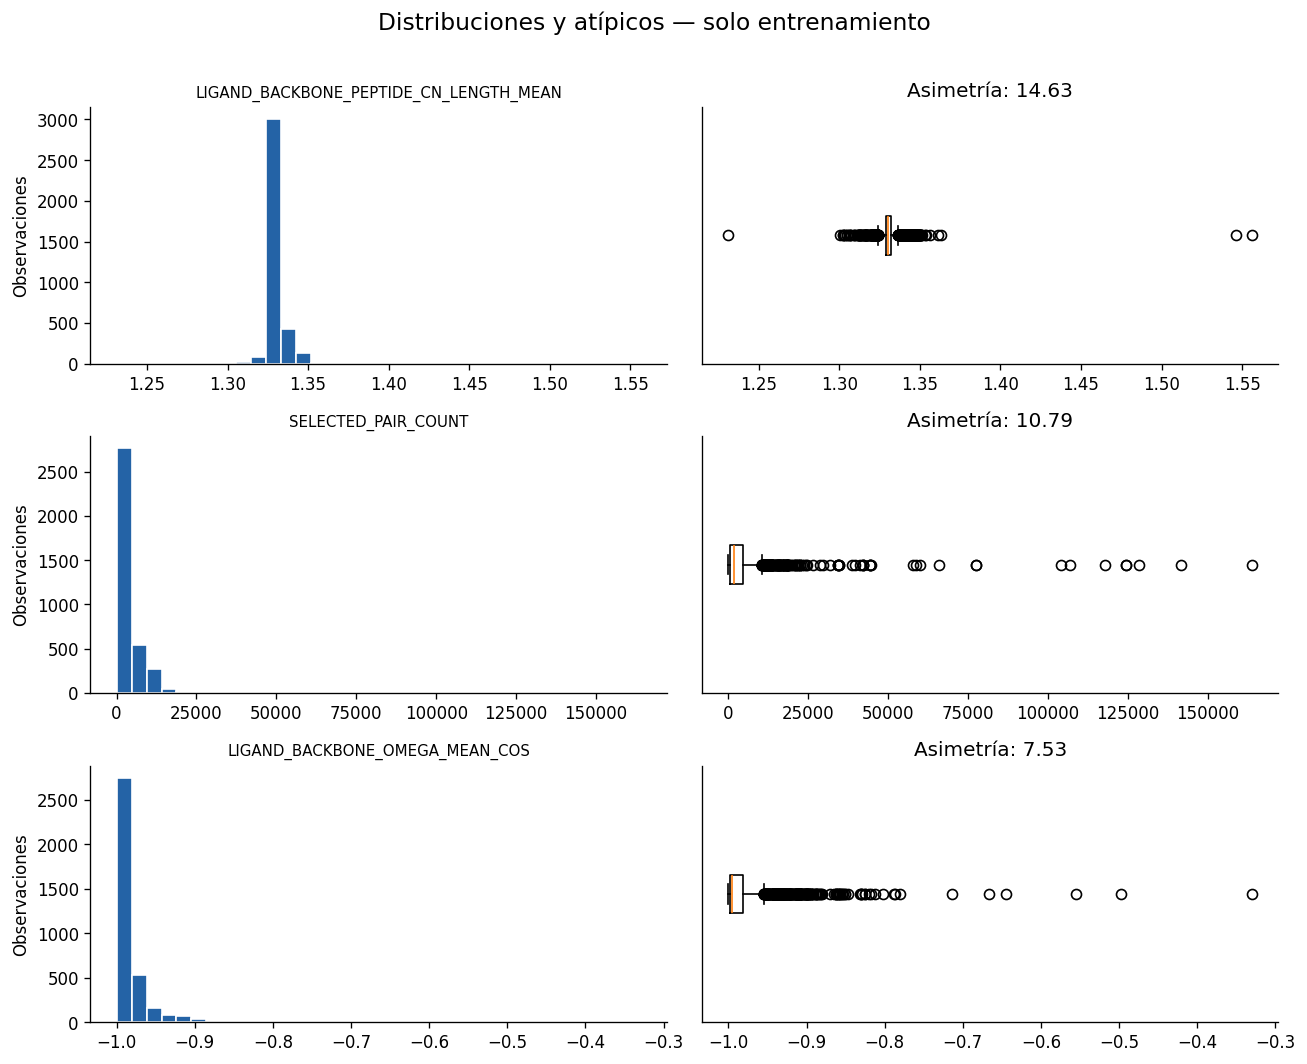

In [3]:
estadisticas=pd.read_csv(eda/"estadisticas_features.csv",index_col="feature")
seleccion=estadisticas.asimetria.abs().sort_values(ascending=False).head(3).index
fig,axes=plt.subplots(3,2,figsize=(11,9))
for i,col in enumerate(seleccion):
    v=train[col].replace([np.inf,-np.inf],np.nan).dropna()
    axes[i,0].hist(v,bins=35,color=AZUL,edgecolor="white")
    axes[i,0].set_title(col,fontsize=9,wrap=True)
    axes[i,0].set_ylabel("Observaciones")
    axes[i,1].boxplot(v,vert=False,whis=1.5)
    axes[i,1].set_title(f"Asimetría: {estadisticas.loc[col,'asimetria']:.2f}")
    axes[i,1].set_yticks([])
fig.suptitle("Distribuciones y atípicos — solo entrenamiento",fontsize=14)
fig.tight_layout(rect=[0,0,1,.97]);guardar(fig,"02_asimetria_boxplots_train")


## 3. Mapa de correlación de Spearman
Para mantener legibilidad, mostramos los 12 predictores con mayor correlación absoluta con PKD en entrenamiento. La matriz completa permanece en el CSV del EDA. Esta vista no elimina ni selecciona features para entrenar.


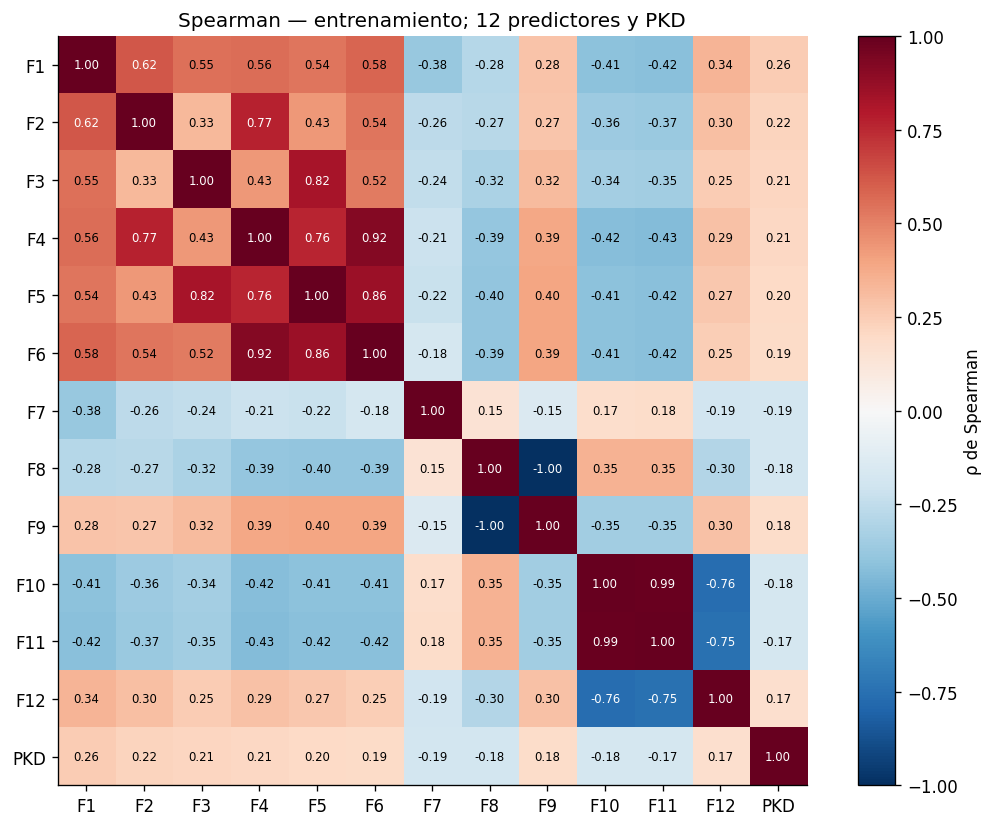

,etiqueta,variable
0,F1,LIGAND_CHEM_FRACTION_POLAR_UNCHARGED
1,F2,LIGAND_CHEM_FRACTION_AA_S
2,F3,LIGAND_CHEM_FRACTION_AA_Y
3,F4,LIGAND_CHEM_N_AA_S
4,F5,LIGAND_CHEM_N_AA_Y
5,F6,LIGAND_CHEM_N_POLAR_UNCHARGED
6,F7,LIGAND_CHEM_FRACTION_BASIC
7,F8,LIGAND_BACKBONE_OMEGA_RESULTANT_LENGTH
8,F9,LIGAND_BACKBONE_OMEGA_CIRCULAR_VARIANCE
9,F10,LIGAND_BACKBONE_PHI_MEAN_COS


In [4]:
rel=pd.read_csv(eda/"correlaciones_pkd_spearman.csv",index_col="feature")
cols=rel.rho_absoluto.nlargest(12).index.tolist()
mat=train[cols+[manifest["target"]]].corr(method="spearman",min_periods=3)
labels=[f"F{i+1}" for i in range(len(cols))]+["PKD"]
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(mat,vmin=-1,vmax=1,cmap="RdBu_r")
ax.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,title="Spearman — entrenamiento; 12 predictores y PKD")
for i in range(len(labels)):
    for j in range(len(labels)):
        value=mat.iloc[i,j]
        ax.text(j,i,f"{value:.2f}",ha="center",va="center",fontsize=7,color="white" if abs(value)>.6 else "black")
fig.colorbar(im,ax=ax,label="ρ de Spearman")
fig.tight_layout();guardar(fig,"03_correlaciones_train")
leyenda=pd.DataFrame({"etiqueta":labels,"variable":cols+[manifest["target"]]})
leyenda.to_csv(OUT/"leyenda_correlaciones.csv",index=False)
display(leyenda)


## 4. Comparación inicial y sobreajuste
Las barras de error son desviaciones entre folds, **no intervalos de confianza**. Las métricas train incluyen los casos obligatorios y CV los excluye. Se usan las corridas corregidas con hiperparámetros por defecto.


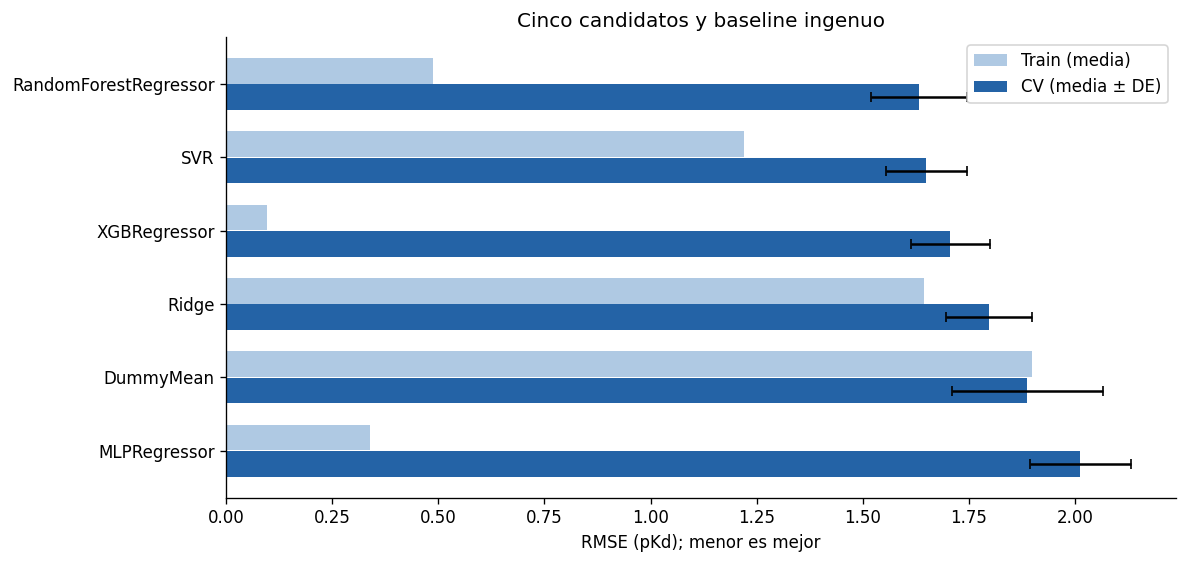

In [5]:
b=baseline.sort_values("rmse_mean")
pos=np.arange(len(b));fig,ax=plt.subplots(figsize=(10,4.8))
ax.barh(pos-.18,b.train_rmse_mean,height=.35,label="Train (media)",color="#AFC9E3")
ax.barh(pos+.18,b.rmse_mean,height=.35,xerr=b.rmse_std,capsize=3,label="CV (media ± DE)",color=AZUL)
ax.set(yticks=pos,yticklabels=b.index,xlabel="RMSE (pKd); menor es mejor",title="Cinco candidatos y baseline ingenuo")
ax.invert_yaxis();ax.legend();fig.tight_layout();guardar(fig,"04_baseline_train_cv")


## 5. Efecto del tuning
Se comparan las versiones iniciales con las mejores configuraciones de la cuadrícula. Las mejoras no superaron la variación entre folds según el criterio aplicado del PSet.


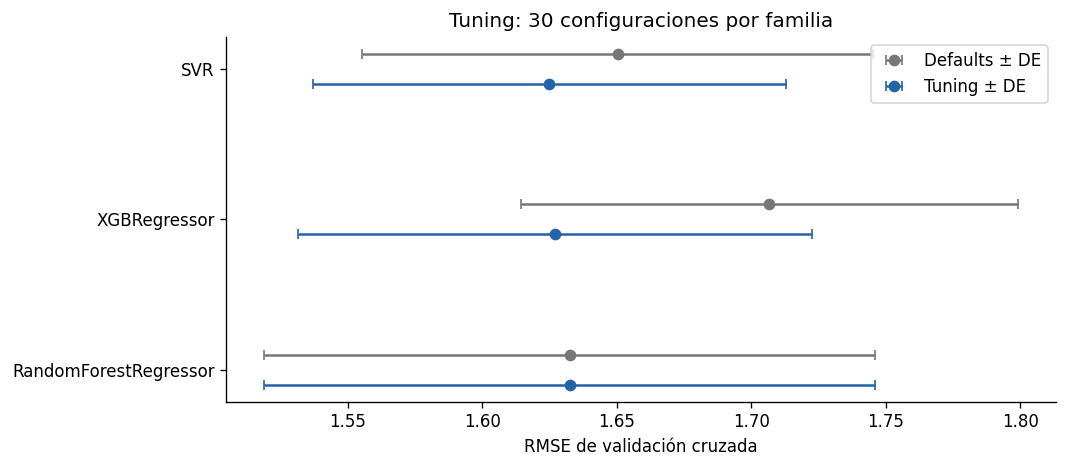

In [6]:
t=tuning.sort_values("rmse_cv");pos=np.arange(len(t))
fig,ax=plt.subplots(figsize=(9,4))
ax.errorbar(t.rmse_baseline,pos-.10,xerr=baseline.loc[t.index,"rmse_std"],fmt="o",capsize=3,color="#777777",label="Defaults ± DE")
ax.errorbar(t.rmse_cv,pos+.10,xerr=t.rmse_cv_std,fmt="o",capsize=3,color=AZUL,label="Tuning ± DE")
ax.set(yticks=pos,yticklabels=t.index,xlabel="RMSE de validación cruzada",title="Tuning: 30 configuraciones por familia")
ax.invert_yaxis();ax.legend();fig.tight_layout();guardar(fig,"05_tuning_cv")


## 6. Predicciones finales ya congeladas
Se reutilizan los archivos guardados en 05 y se verifica su integridad. La línea diagonal representa predicción perfecta. No se reajusta ningún modelo ni se modifica la selección.


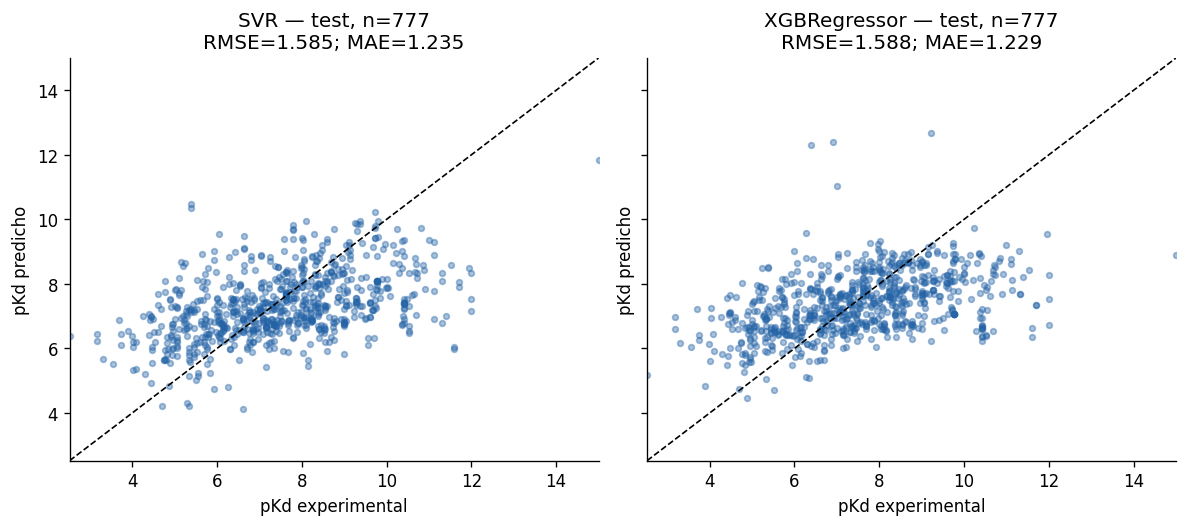

In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,4.5),sharex=True,sharey=True)
pares={}
policy_hash=hashlib.sha256((ROOT/"configs/evaluacion_final.json").read_bytes()).hexdigest()
for nombre in ["SVR","XGBRegressor"]:
    archivo=final_dir/f"predicciones_{nombre}.parquet"
    meta=json.loads((final_dir/f"predicciones_{nombre}.json").read_text())
    assert meta["policy_sha256"]==policy_hash
    assert hashlib.sha256(archivo.read_bytes()).hexdigest()==meta["prediction_sha256"]
    pares[nombre]=pd.read_parquet(archivo)
lo=min(float(d.min().min()) for d in pares.values());hi=max(float(d.max().max()) for d in pares.values())
for ax,(nombre,d) in zip(axes,pares.items()):
    ax.scatter(d.pkd_real,d.pkd_predicho,s=12,alpha=.4,color=AZUL,rasterized=True)
    ax.plot([lo,hi],[lo,hi],"--",color="black",linewidth=1)
    ax.set(xlabel="pKd experimental",ylabel="pKd predicho",title=f"{nombre} — test, n={len(d)}\nRMSE={final.loc[nombre,'rmse']:.3f}; MAE={final.loc[nombre,'mae']:.3f}",xlim=(lo,hi),ylim=(lo,hi))
fig.tight_layout();guardar(fig,"06_predicciones_test")


## 7. Resultado de negocio: aciertos, precisión y recuperación
La referencia aleatoria usa el mismo cupo; su barra muestra percentiles 2,5–97,5 de selecciones aleatorias, no incertidumbre del modelo. El recall máximo posible con este cupo es K/positivos disponibles. El ahorro monetario no se grafica como superioridad del modelo: es idéntico para cualquier método que mida solo K casos.


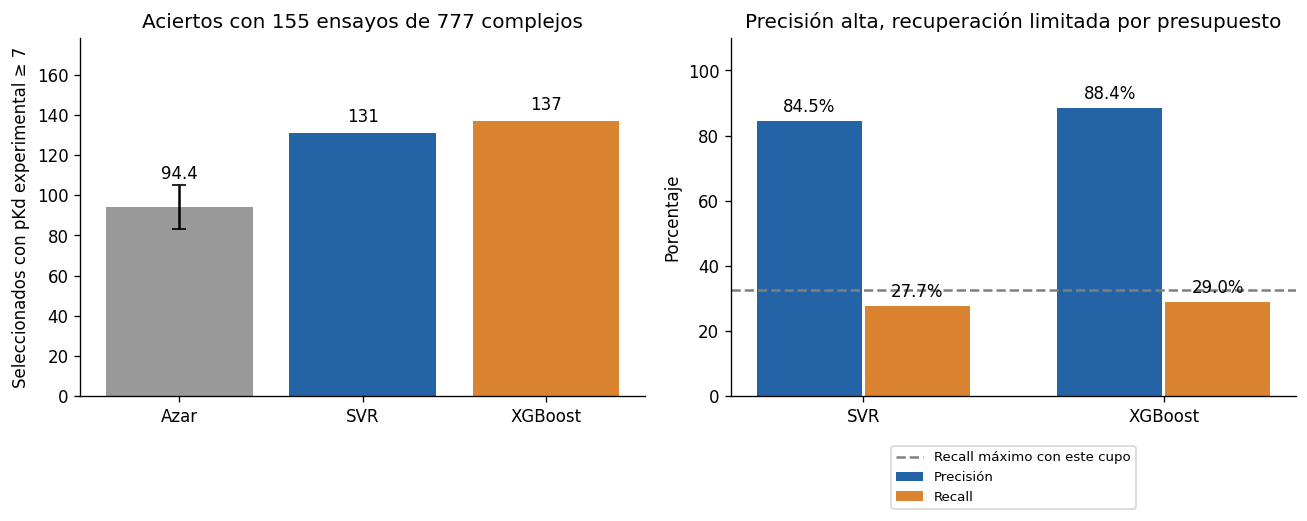

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
metodos=["Azar", "SVR", "XGBoost"]
hits=[azar["aciertos_esperados"],final.loc["SVR","aciertos"],final.loc["XGBRegressor","aciertos"]]
bars=axes[0].bar(metodos,hits,color=["#999999",AZUL,NARANJA])
axes[0].bar_label(bars,labels=["" if i==0 else str(int(v)) for i,v in enumerate(hits)],padding=4)
axes[0].errorbar(0,hits[0],yerr=[[hits[0]-azar["percentil_2_5"]],[azar["percentil_97_5"]-hits[0]]],fmt="none",ecolor="black",capsize=4)
axes[0].text(0,azar["percentil_97_5"]+3,f"{hits[0]:.1f}",ha="center")
axes[0].set(ylabel="Seleccionados con pKd experimental ≥ 7",title=f"Aciertos con {azar['K']} ensayos de {azar['N']} complejos",ylim=(0,azar['K']*1.15))
pos=np.arange(2);rows=final.loc[["SVR","XGBRegressor"]]
a=axes[1].bar(pos-.18,100*rows.precision_seleccion,.35,label="Precisión",color=AZUL)
b=axes[1].bar(pos+.18,100*rows.recuperacion,.35,label="Recall",color=NARANJA)
for bars in [a,b]:axes[1].bar_label(bars,fmt="%.1f%%",padding=3)
axes[1].axhline(100*azar['K']/azar['positivos_disponibles'],linestyle="--",color="gray",label="Recall máximo con este cupo")
axes[1].set(xticks=pos,xticklabels=["SVR","XGBoost"],ylabel="Porcentaje",ylim=(0,110),title="Precisión alta, recuperación limitada por presupuesto")
axes[1].legend(fontsize=8,loc="upper center",bbox_to_anchor=(.5,-.12))
fig.tight_layout();guardar(fig,"07_negocio_test")


## 8. Archivos listos para el memo
Las siete figuras se guardan en PNG para insertar en documentos y PDF para conservar calidad al escalar. No se sustituyen tablas de resultados ni se producen nuevas predicciones.


In [9]:
(OUT/"manifest.json").write_text(json.dumps({"snapshot":snapshot,"source_sha256":split["source_sha256"],"policy_sha256":policy_hash,
    "source_notebooks":"01–05, artefactos guardados", "training_figures":figuras[:5],"frozen_test_figures":figuras[5:],
    "files_sha256":{f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in OUT.glob("*.png")}},indent=2))
display(pd.DataFrame({"figura":figuras,"PNG":[str(OUT/f"{f}.png") for f in figuras]}))


,figura,PNG
0,01_target_train,/workspace/reports/figuras/20261118T0441589535...
1,02_asimetria_boxplots_train,/workspace/reports/figuras/20261118T0441589535...
2,03_correlaciones_train,/workspace/reports/figuras/20261118T0441589535...
3,04_baseline_train_cv,/workspace/reports/figuras/20261118T0441589535...
4,05_tuning_cv,/workspace/reports/figuras/20261118T0441589535...
5,06_predicciones_test,/workspace/reports/figuras/20261118T0441589535...
6,07_negocio_test,/workspace/reports/figuras/20261118T0441589535...
